# ECE284 Part1 — completed W4A4 VGG16 run

This completed notebook records 90.94% CIFAR-10 test accuracy and maximum absolute reconstruction error 4.076379191531032e-6 for fixed test sample 0.

For this repository copy, the stale untrained-status introduction was replaced and the original machine-specific project path in outputs was replaced with `<PROJECT_ROOT>`. Other code and outputs are retained. Use the root `Part1_Run.ipynb` to launch a new run.


In [1]:
from pathlib import Path
import sys, os, subprocess, json, csv
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "train.py").is_file():
    candidate = PROJECT_ROOT / "ECE284_Part1"
    if candidate.is_dir():
        PROJECT_ROOT = candidate
    else:
        raise FileNotFoundError("请在解压后的 ECE284_Part1 文件夹打开 notebook，保留同目录的 .py 文件。")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import torch
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("当前无 CUDA。快速检查可在 CPU 运行；正式训练建议切换 DSMLP GPU 环境。")


Project: <PROJECT_ROOT>
Python: /opt/conda/bin/python
Torch: 2.2.1+cu121
CUDA: True
GPU: NVIDIA GeForce GTX 1080 Ti


## 1. 先检查模型和量化配置

首层输入是标准化 RGB，可能含负值，采用 signed 4-bit；其他卷积的 ReLU 输入采用 unsigned 4-bit。分类 Linear 和 BN 参数保留浮点。选定的硬件层没有 bias，后面只有 ReLU，因此能够直接比较整数恢复值与下一卷积的输入。

In [2]:
from models import build_model, QuantConv2d
model = build_model(quantize=True)
print(model.features[24:31])
print(json.dumps(model.architecture_config(), indent=2))
assert model.features[27].in_channels == model.features[27].out_channels == 8
assert isinstance(model.features[28], torch.nn.ReLU)
assert isinstance(model.features[29], QuantConv2d)
assert len([m for m in model.modules() if isinstance(m, QuantConv2d)]) == 13
# 释放本单元模型；训练脚本会创建自己的模型。
del model


Sequential(
  (24): QuantConv2d(256, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, a_bit=4, w_bit=4, signed_activation=False)
  (25): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (26): ReLU()
  (27): QuantConv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, a_bit=4, w_bit=4, signed_activation=False)
  (28): ReLU()
  (29): QuantConv2d(8, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False, a_bit=4, w_bit=4, signed_activation=False)
  (30): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)
{
  "model": "VGG16QAT",
  "dataset": "CIFAR10",
  "num_classes": 10,
  "input_shape": [
    3,
    32,
    32
  ],
  "feature_configuration": [
    64,
    64,
    "M",
    128,
    128,
    "M",
    256,
    256,
    256,
    "M",
    8,
    8,
    512,
    "M",
    512,
    512,
    512,
    "M"
  ],
  "convolution_count": 13,
  "quantized_convolution_count": 13,
  "activati

## 2. 运行独立检查

这一步无需 CIFAR-10，检查量化梯度、真实下一层 prehook、int64 卷积和导出的二进制布局。完成这一步不代表准确率达到 90%。

In [3]:
subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], check=True)


test_actual_downstream_change_cannot_pass_using_a_computed_reference (test_part1.Part1Tests.test_actual_downstream_change_cannot_pass_using_a_computed_reference) ... ok
test_course_quantizer_forward_and_saturation_gradient_conventions (test_part1.Part1Tests.test_course_quantizer_forward_and_saturation_gradient_conventions) ... ok
test_downstream_prehook_reconstruction_and_hardware_file_readback (test_part1.Part1Tests.test_downstream_prehook_reconstruction_and_hardware_file_readback) ... ok
test_first_convolution_quantizes_signed_normalized_rgb_inputs (test_part1.Part1Tests.test_first_convolution_quantizes_signed_normalized_rgb_inputs) ... ok
test_integer_reference_matches_literal_cross_correlation (test_part1.Part1Tests.test_integer_reference_matches_literal_cross_correlation) ... ok
test_quantized_convolution_trains_weights_and_clip_parameters (test_part1.Part1Tests.test_quantized_convolution_trains_weights_and_clip_parameters) ... ok
test_quantizers_have_correct_lattices_and_straight

CompletedProcess(args=['/opt/conda/bin/python', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0)

## 3. 配置正式训练

第一次保持 `ACTION="train"`；中断后保留原配置，将它改为 `"resume"`；只重新测已有模型则设为 `"evaluate"`。

默认 200 epoch，从头执行 QAT。第一次自动下载 CIFAR-10。`best.pth` 保存全测试集准确率最高的 QAT 模型。此流程沿用课程参考的选模方式，测试集不属于研究意义上未触碰的 holdout。

In [4]:
ACTION = "train"          # "train" / "resume" / "evaluate"
DEVICE = "auto"           # 自动优先 CUDA，其次 MPS，最后 CPU
DATA_ROOT = PROJECT_ROOT / "data"
RUN_DIR = PROJECT_ROOT / "runs" / "part1"
QAT_EPOCHS = 200
BATCH_SIZE = 128
WORKERS = 2
SEED = 284
DETERMINISTIC = False
ALLOW_CPU_TRAINING = False
print("Action:", ACTION, "Output:", RUN_DIR)


Action: train Output: <PROJECT_ROOT>/runs/part1


## 4. 正式训练、完整测试及导出

这一单元耗时最长。每个 epoch 打印 train/test accuracy 并保存 `last.pth`，支持中断恢复。

完成后自动重载 `best.pth`，重新测试 10,000 张 CIFAR-10 测试图像，再对固定 test index 0 进行整数重算和向量导出。**只有运行产生的数据才是最终结果。**

In [5]:
from train import choose_device
actual_device = choose_device(DEVICE)
if actual_device.type == "cpu" and not ALLOW_CPU_TRAINING:
    raise RuntimeError("当前只有 CPU。请切换 DSMLP GPU 环境后运行；若明确要 CPU 长时间训练，再将 ALLOW_CPU_TRAINING=True。")
if ACTION not in {"train", "resume", "evaluate"}:
    raise ValueError("ACTION 必须为 train、resume 或 evaluate")
command = [sys.executable, "train.py", "--device", DEVICE,
           "--data-root", str(DATA_ROOT), "--output", str(RUN_DIR),
           "--qat-epochs", str(QAT_EPOCHS), "--batch-size", str(BATCH_SIZE),
           "--workers", str(WORKERS), "--seed", str(SEED)]
if DETERMINISTIC:
    command += ["--deterministic"]
if ACTION == "resume":
    command += ["--resume", str(RUN_DIR / "last.pth")]
elif ACTION == "evaluate":
    command += ["--evaluate", str(RUN_DIR / "best.pth")]
print("Running:", " ".join(command))
completed = subprocess.run(command)
if completed.returncode != 0:
    if completed.returncode == 2 and (RUN_DIR / "results.json").is_file():
        print("运行结束，但 accuracy 或误差条件尚未全部通过。请查看下一单元的实际结果。")
    else:
        raise RuntimeError(f"运行错误，返回码 {completed.returncode}；请检查上方具体报错。")


Running: /opt/conda/bin/python train.py --device auto --data-root <PROJECT_ROOT>/data --output <PROJECT_ROOT>/runs/part1 --qat-epochs 200 --batch-size 128 --workers 2 --seed 284


100%|██████████| 170498071/170498071 [25:27<00:00, 111606.68it/s]


Extracting <PROJECT_ROOT>/data/cifar-10-python.tar.gz to <PROJECT_ROOT>/data
Files already downloaded and verified
qat epoch 1/200: train=38.71% test=49.25% best_QAT=49.25% lr=0.02 time=37.3s
qat epoch 2/200: train=57.37% test=61.00% best_QAT=61.00% lr=0.02 time=32.5s
qat epoch 3/200: train=66.48% test=62.20% best_QAT=62.20% lr=0.02 time=32.5s
qat epoch 4/200: train=71.00% test=71.41% best_QAT=71.41% lr=0.02 time=31.8s
qat epoch 5/200: train=74.07% test=69.64% best_QAT=71.41% lr=0.02 time=31.9s
qat epoch 6/200: train=76.12% test=75.10% best_QAT=75.10% lr=0.02 time=33.1s
qat epoch 7/200: train=78.10% test=77.32% best_QAT=77.32% lr=0.02 time=32.5s
qat epoch 8/200: train=79.36% test=77.60% best_QAT=77.60% lr=0.02 time=32.4s
qat epoch 9/200: train=80.72% test=79.19% best_QAT=79.19% lr=0.02 time=32.5s
qat epoch 10/200: train=81.61% test=75.54% best_QAT=79.19% lr=0.02 time=33.0s
qat epoch 11/200: train=82.44% test=80.64% best_QAT=80.64% lr=0.02 time=33.0s
qat epoch 12/200: train=83.10% test=

## 5. 看最终结果，不用 signed error sum 判定

正式成功条件是 test accuracy **>90%** 和最大绝对误差 **<1e-3**。正文更严格的 **<1e-5** 也会单独报告。Float32 累加可能让更严格的条件失败，即使整数与硬件验证正确；请如实保留两项结果。

In [6]:
results_path = RUN_DIR / "results.json"
if not results_path.is_file():
    raise FileNotFoundError("还没有正式训练/测试结果。先完成上一单元。")
results = json.loads(results_path.read_text())
assert results["evidence_type"] == "trained_model"
print(json.dumps(results, indent=2, ensure_ascii=False))
print("\n报告可填写的实际数值：")
print(f"Accuracy: {results['test_accuracy_pct']:.4f}% ({results['correct']}/{results['total']})")
print(f"Max absolute reconstruction error: {results['max_abs_error']:.10g}")
print("Formal success:", results["status"])
print("Strict <1e-5:", results["error_lt_1e_5"])


{
  "status": "PASS",
  "evidence_type": "trained_model",
  "dataset": "CIFAR10",
  "test_accuracy_pct": 90.94,
  "correct": 9094,
  "total": 10000,
  "accuracy_gt_90": true,
  "max_abs_error": 4.076379191531032e-06,
  "error_lt_1e_5": true,
  "error_lt_1e_3": true,
  "architecture": {
    "model": "VGG16QAT",
    "dataset": "CIFAR10",
    "num_classes": 10,
    "input_shape": [
      3,
      32,
      32
    ],
    "feature_configuration": [
      64,
      64,
      "M",
      128,
      128,
      "M",
      256,
      256,
      256,
      "M",
      8,
      8,
      512,
      "M",
      512,
      512,
      512,
      "M"
    ],
    "convolution_count": 13,
    "quantized_convolution_count": 13,
    "activation_bits": 4,
    "weight_bits": 4,
    "activation_integer_range": [
      0,
      15
    ],
    "first_activation_integer_range": [
      -7,
      7
    ],
    "first_activation_signed": true,
    "weight_integer_range": [
      -7,
      7
    ],
    "floating_point_la

## 6. 训练曲线

用于说明训练是否收敛以及 QAT 测试准确率是否达到目标。曲线来自 `history.csv`，没有预填结果。

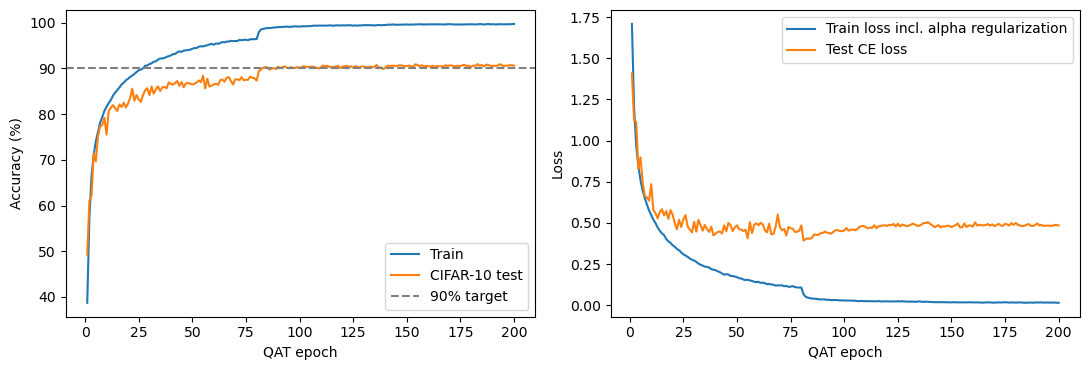

In [7]:
import matplotlib.pyplot as plt
history_path = RUN_DIR / "history.csv"
with history_path.open() as f:
    records = list(csv.DictReader(f))
qat = [r for r in records if r["phase"] == "qat"]
if not qat:
    raise RuntimeError("没有 QAT epoch 记录")
x = [int(r["epoch"]) for r in qat]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(x, [float(r["train_accuracy_pct"]) for r in qat], label="Train")
axes[0].plot(x, [float(r["test_accuracy_pct"]) for r in qat], label="CIFAR-10 test")
axes[0].axhline(90, color="gray", linestyle="--", label="90% target")
axes[0].set(xlabel="QAT epoch", ylabel="Accuracy (%)")
axes[0].legend()
axes[1].plot(x, [float(r["train_loss"]) for r in qat], label="Train loss incl. alpha regularization")
axes[1].plot(x, [float(r["test_loss"]) for r in qat], label="Test CE loss")
axes[1].set(xlabel="QAT epoch", ylabel="Loss")
axes[1].legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=180)
plt.show()


## 7. 与 Part4 交接

交接整个 `runs/part1/vectors/`，保持文件相对路径。`input.txt` 是 padded activation，`weight.txt` 是合并权重，`psum.txt` 是 **整数域 ReLU 后期望值**。旧 testbench 使用 `activation/`、`weights/`、`output/` 和 `acc_address.txt`。

文件位序、scales、样本索引和模型 SHA256 都在 metadata 中。硬件验证通过后，组内 RTL 负责人还需完成 SFU 结果写回 SRAM 的要求；本 notebook 只负责 Part1 及数据接口。

In [8]:
vector_dir = RUN_DIR / "vectors"
metadata = json.loads((vector_dir / "metadata.json").read_text())
print("Model fingerprint:", metadata["model_sha256"])
print("Dataset provenance:", metadata["provenance"])
print(json.dumps(metadata["vectors"], indent=2, ensure_ascii=False))
print("交接目录:", vector_dir)


Model fingerprint: 747dc1546f41df96d02b3b8936d796bc38b11bafba9edbd8713f84c07a39ccad
Dataset provenance: {'checkpoint': '<PROJECT_ROOT>/runs/part1/best.pth', 'dataset': 'CIFAR10', 'dataset_index': 0, 'evidence_type': 'trained_model', 'label': 3, 'note': 'Fixed test index; the sample was not selected by verification error.', 'split': 'test', 'validation': {'accuracy_pct': 90.94, 'correct': 9094, 'loss': 0.4803284370422363, 'total': 10000}}
{
  "accumulation_addresses": "acc_address.txt",
  "activation": "activation/activation.txt",
  "activation_encoding": "unsigned 4-bit (0..15)",
  "activation_word_bits": 32,
  "activation_words": 36,
  "address_word_bits": 11,
  "address_words": 144,
  "aliases": {
    "input.txt": "Byte-identical alias of activation/activation.txt",
    "psum.txt": "Byte-identical alias of output/output_after_relu.txt",
    "weight.txt": "Three header tokens, then nine kernel blocks of eight words"
  },
  "compatibility": "Part3alpha/verilog/core_tb.v, run from expor

## 8. 报告 Part1 应写什么

用你刚运行出的结果填写：

1. 模型修改：目标层位置、前后通道衔接、8→8、去掉该层后的 BN。
2. 量化方法：W4A4、首层 signed 输入、其他层 unsigned 输入、权重量化前的标准化、learned clipping。
3. 训练设置和实际完整测试准确率，附训练曲线。
4. 验证方法：int64 卷积与 ReLU，恢复到模型数值域，比较下一卷积真实 prehook 输入。
5. 实际最大绝对误差，以及 `<1e-5` 和 `<1e-3` 两个判断。
6. 推论：模型保留的分类能力如何，以及整数计算与量化模型是否数值一致。

保留 `best.pth`、代码、notebook、日志、results 和 vectors，便于组内整合。提交格式以课程最终说明为准。
正式测试结束后，脚本还会生成 `runs/part1/part1_report.txt`，包含实际数值的英文初稿。
